<a href="https://colab.research.google.com/github/teddiclax/Carbon__Deposition__Prediction-Catalytic-Methane-Pyrolysis-/blob/teddiclax/MASS__OF__CARBON__DEPOSITION__CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
### PRELIMINARY DATA ANALYSIS ###

## Importing necessary libriaries for the preliminary analysis ##
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import r2_score

## Import dataset ##
raw_df = pd.read_csv('/content/Carbon___Mass___Deposition___Data.csv')
raw_df.columns = [c.strip() for c in raw_df.columns]

## Configuring Operational Filtering ##
## Here, M_C_kg > 0 and SEC_kWh_per_kgC notna ##

df_operational = raw_df[(raw_df["M_C_kg"] > 0) & (raw_df["SEC_kWh_per_kgC"].notna())].copy()
num_cols = [
    "Fo_CH4_m3_per_h", "T_C", "X_CH4_conv_pct", "P_input_W", "TOS_h",
    "L_m", "D_m", "A_m2", "M_C_kg", "CFR_kg_per_h", "Y_C_feed_pct", "SEC_kWh_per_kgC"
]
for c in num_cols:
    df_operational[c] = pd.to_numeric(df_operational[c], errors="coerce")

## Drop rows with NaNs in key derived variables ##
df_operational.dropna(subset=["SEC_kWh_per_kgC", "M_C_kg"], inplace=True)
print("Operational rows:", len(df_operational), "out of", len(raw_df))
print()

## Carry out descriptive statistics of the varibales ##
print("### 1. Descriptive Statistics of Key Variables:\n###")
desc_stats = df_operational[["SEC_kWh_per_kgC", "Y_C_feed_pct", "M_C_kg", "CFR_kg_per_h"]].describe()
print(desc_stats)
print("\n")

## Correlation Analysis ##
correlation_cols = [
    "P_input_W", "Fo_CH4_m3_per_h", "X_CH4_conv_pct", "T_C", "TOS_h",
    "SEC_kWh_per_kgC", "Y_C_feed_pct", "M_C_kg", "CFR_kg_per_h"
]
corr_df = df_operational.dropna(subset=correlation_cols)[correlation_cols]
correlation_matrix = corr_df.corr(numeric_only=True)
print("### 2. Correlation Matrix of Key Parameters:\n###")
print(correlation_matrix)
print("\n")




## Binned Analysis of Specific Energy Consumption (SEC_kWh_per_kgC) by Temerature (T_C) ##
bins = [300, 350, 400, 450, 500, 550, 600, 650]
labels = ["300-350", "351-400", "401-450", "451-500", "501-550", "551-600", "601-650"]
df_operational["T_bin"] = pd.cut(df_operational["T_C"], bins=bins, labels=labels, right=True, include_lowest=True)
binned_sec_analysis = df_operational.groupby("T_bin")["SEC_kWh_per_kgC"].agg(["mean", "median", "min", "max", "count"])
print("### 3. Binned Analysis of SEC by Temperature (T_C):\n###")
print(binned_sec_analysis)
print("\n")

## Most Energy-Efficient Row ##
if not df_operational.empty:
    idx = df_operational["SEC_kWh_per_kgC"].idxmin()
    optimal_row_sec = df_operational.loc[idx]
    print("### 4. Most Energy-Efficient Operating Point (Lowest SEC_kWh_per_kgC):\n###")
    show_cols = [
        "P_input_W","Fo_CH4_m3_per_h","T_C","X_CH4_conv_pct","TOS_h",
        "M_C_kg","CFR_kg_per_h","Y_C_feed_pct","SEC_kWh_per_kgC"
    ]
    print(optimal_row_sec[show_cols].to_string())
else:
    print("No operational data available (M_C_kg > 0 and SEC_kWh_per_kgC notna). Cannot identify optimal point.")
print("\n")

Operational rows: 95 out of 100

### 1. Descriptive Statistics of Key Variables:
###
       SEC_kWh_per_kgC  Y_C_feed_pct     M_C_kg  CFR_kg_per_h
count        95.000000     95.000000  95.000000     95.000000
mean      17666.595903     40.344618   0.002387      0.000456
std       25253.231375     19.435063   0.001699      0.000455
min        4422.083333      3.240286   0.000100      0.000000
25%        6453.125000     23.004995   0.000925      0.000000
50%        9381.250000     46.610274   0.002000      0.000400
75%       15035.937500     58.235147   0.003700      0.000800
max      144250.000000     82.627303   0.006000      0.001600


### 2. Correlation Matrix of Key Parameters:
###
                 P_input_W  Fo_CH4_m3_per_h  X_CH4_conv_pct       T_C  \
P_input_W         1.000000        -0.422129       -0.710152 -0.373814   
Fo_CH4_m3_per_h  -0.422129         1.000000        0.146156  0.047337   
X_CH4_conv_pct   -0.710152         0.146156        1.000000  0.215604   
T_C           

/tmp/ipython-input-3152155866.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned_sec_analysis = df_operational.groupby("T_bin")["SEC_kWh_per_kgC"].agg(["mean", "median", "min", "max", "count"])


In [2]:
### Configuring a grid search function for obtainied the optimal architectural configuratiohn accross the PINN_M1, PINN_M2 and the Classic-FNN  ###

## Importing necessary libriaries for the preliminary analysis ##
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
## Configure the Grid Search ##
ACTIVATIONS = ["Tanh", "ReLU", "GELU"]
ARCHITECTURES = [[64, 64], [128, 64], [256, 128]]

## Evaluation Utility ##
def evaluate_model(model, X_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(X_val).cpu().numpy()
        y_true = y_val.cpu().numpy()
    return r2_score(y_true, y_pred)

## Shared Architecture Search ##
def search_shared_architecture(
    FNNClass, PINN1Class, PINN2Class,
    train_fnn, train_pinn1, train_pinn2,
    X_tr_t, y_tr_t, X_va_t, y_va_t,
    X_tr_phys_t=None, X_va_phys_t=None
):
    shared_results = []

    for act in ACTIVATIONS:
        for hidden in ARCHITECTURES:
            print(f"\n🔍 Trying shared config: activation={act}, hidden={hidden}")

            ## Classsic-FNN ##
            fnn_model = FNNClass(input_dim=X_tr_t.shape[1], hidden=hidden[0], activation=act).to(X_tr_t.device)
            fnn_trained = train_fnn(fnn_model, X_tr_t, y_tr_t, X_va_t, y_va_t)
            fnn_r2 = evaluate_model(fnn_trained, X_va_t, y_va_t)

            ## PINN_M1 Model ##
            pinn1_model = PINN1Class(input_dim=X_tr_t.shape[1], hidden=hidden[0], activation=act).to(X_tr_t.device)
            pinn1_trained = train_pinn1(pinn1_model, X_tr_t, y_tr_t, X_va_t, y_va_t, X_tr_phys_t, X_va_phys_t)
            pinn1_r2 = evaluate_model(pinn1_trained, X_va_t, y_va_t)

            ## PINN_M2 Model ##
            pinn2_model = PINN2Class(input_dim=X_tr_t.shape[1], hidden=hidden[0], activation=act).to(X_tr_t.device)
            pinn2_trained = train_pinn2(pinn2_model, X_tr_t, y_tr_t, X_va_t, y_va_t, X_tr_phys_t, X_va_phys_t)
            pinn2_r2 = evaluate_model(pinn2_trained, X_va_t, y_va_t)

            avg_r2 = np.mean([fnn_r2, pinn1_r2, pinn2_r2])
            shared_results.append({
                "activation": act,
                "hidden": hidden,
                "avg_r2": avg_r2,
                "fnn_r2": fnn_r2,
                "pinn1_r2": pinn1_r2,
                "pinn2_r2": pinn2_r2
            })

    best_config = max(shared_results, key=lambda x: x["avg_r2"])

    print("\n" + "#"*60)
    print("✅ BEST SHARED NEURAL NETWORK CONFIGURATION")
    print("#"*60)
    print(f"Activation function : {best_config['activation']}")
    print(f"Hidden layer sizes  : {best_config['hidden']}")
    print(f"\nPerformance (Validation R²):")
    print(f"  FNN      : R² = {best_config['fnn_r2']:.4f}")
    print(f"  PINN_M1  : R² = {best_config['pinn1_r2']:.4f}")
    print(f"  PINN_M2  : R² = {best_config['pinn2_r2']:.4f}")
    print(f"  AVERAGE  : R² = {best_config['avg_r2']:.4f}")
    print("#"*60)

    return best_config

In [3]:
### Defining the - Classic-FNN, PINN-M1 and PINN-M2 ###
class FNN(nn.Module):
    def __init__(self, input_dim, hidden=64, activation="Tanh"):
        super().__init__()
        act = getattr(nn, activation)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), act(),
            nn.Linear(hidden, hidden), act(),
            nn.Linear(hidden, 1),
            nn.Softplus()
        )
    def forward(self, x):
        return self.net(x)

### PINN_M1 (Arrhenius + Power Law model) ###
class ArrheniusPINN(nn.Module):
    def __init__(self, input_dim, hidden=64, activation="Tanh"):
        super().__init__()
        act = getattr(nn, activation)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), act(),
            nn.Linear(hidden, hidden), act(),
            nn.Linear(hidden, 1),
            nn.Softplus()
        )
        self.k0_raw   = nn.Parameter(torch.tensor(0.0))
        self.Ea_raw   = nn.Parameter(torch.tensor(0.5))
        self.beta_raw = nn.Parameter(torch.tensor(0.1))

    def forward(self, x):
        return self.net(x)

    def k0(self): return torch.nn.functional.softplus(self.k0_raw)
    def Ea(self): return 1e5 * torch.nn.functional.softplus(self.Ea_raw)
    def beta(self): return torch.nn.functional.softplus(self.beta_raw)

### PINN_M2 (CFR = dM/dt constraint) ###
class PINN_M2(nn.Module):
    def __init__(self, input_dim, hidden=64, activation="Tanh"):
        super().__init__()
        act = getattr(nn, activation)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), act(),
            nn.Linear(hidden, hidden), act(),
            nn.Linear(hidden, 1),
            nn.Softplus()
        )
    def forward(self, x):
        return self.net(x)

In [4]:
## Defining the Training and Validation function for the Classic-FNN ##
def train_fnn(model, X_tr_t, y_tr_t, X_va_t, y_va_t, lr=1e-3, epochs=5000, patience=500):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_loss = float("inf")
    wait = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        pred = model(X_tr_t)
        loss = loss_fn(pred, y_tr_t)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_va_t), y_va_t).item()

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping FNN at epoch {epoch}")
                break

    if best_state:
        model.load_state_dict(best_state)
    return model

In [5]:
## Defining the Training and Validation function for the PINN_M1 model ##
def train_pinn1(model, X_tr_t, y_tr_t, X_va_t, y_va_t, X_tr_phys_t, X_va_phys_t,
                sigma_t=1.0, t_idx=-1, lambda_phys=0.1, lr=1e-3, epochs=5000, patience=500):

    R = 8.314
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss = float("inf")
    wait = 0
    best_state = None

    def rhs(xp, k0, Ea, beta):
        T = xp[:, 0:1] + 273.15
        F = xp[:, 1:2]
        X = xp[:, 2:3] / 100.0
        P = xp[:, 3:4]
        return k0 * torch.exp(-Ea / (R * T)) * F * X * torch.pow(P + 1e-12, beta)

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()

        x = X_tr_t.clone().detach().requires_grad_(True)
        M_pred = model(x)
        loss_data = torch.mean((M_pred - y_tr_t)**2)

        grads = torch.autograd.grad(M_pred, x, torch.ones_like(M_pred), create_graph=True)[0]
        dMdt = grads[:, t_idx:t_idx+1] / sigma_t

        k0, Ea, beta = model.k0(), model.Ea(), model.beta()
        cfr = rhs(X_tr_phys_t, k0, Ea, beta)
        loss_phys = torch.mean((dMdt - cfr)**2)

        loss = loss_data + lambda_phys * loss_phys
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val_loss = torch.mean((model(X_va_t) - y_va_t) ** 2).item()

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.cpu().detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping PINN_M1 at epoch {epoch}")
                break

    if best_state:
        model.load_state_dict(best_state)
    return model

In [6]:
## Defining the Training and Validation function for the PINN_M2 model ##
def train_pinn2(model, X_tr_t, y_tr_t, X_va_t, y_va_t, X_tr_phys_t, X_va_phys_t,
                sigma_t=1.0, t_idx=-1, lambda_phys=0.1, lr=1e-3, epochs=5000, patience=500):

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss = float("inf")
    wait = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()

        x = X_tr_t.clone().detach().requires_grad_(True)
        M_pred = model(x)
        loss_data = torch.mean((M_pred - y_tr_t)**2)

        grads = torch.autograd.grad(M_pred, x, torch.ones_like(M_pred), create_graph=True)[0]
        dMdt = grads[:, t_idx:t_idx+1] / sigma_t

        cfr_true = X_tr_phys_t[:, -1:]  # CFR in last column
        loss_phys = torch.mean((dMdt - cfr_true)**2)

        loss = loss_data + lambda_phys * loss_phys
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val_loss = torch.mean((model(X_va_t) - y_va_t) ** 2).item()

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.cpu().detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping PINN_M2 at epoch {epoch}")
                break

    if best_state:
        model.load_state_dict(best_state)
    return model

In [9]:
## File path and feature settings ##
# SEED = 42
# np.random.seed(SEED)
# torch.manual_seed(SEED)

import random

# Set seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Ensure deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")




CSV_PATH = "/content/Carbon___Mass___Deposition___Data.csv"
feature_cols = ["T_C", "Fo_CH4_m3_per_h", "X_CH4_conv_pct", "P_input_W", "TOS_h"]
target_mass_col = "M_C_kg"
target_cfr_col = "CFR_kg_per_h"
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]

## Convert targets to grams ##
df["M_C_g"] = 1000.0 * df[target_mass_col]
df["CFR_g_per_h"] = 1000.0 * df[target_cfr_col]

## Drop rows with missing values ##
df = df.dropna(subset=feature_cols + ["M_C_g", "CFR_g_per_h"]).copy()

## Extract arrays ##
X = df[feature_cols].to_numpy(dtype=float)
y_mass = df[["M_C_g"]].to_numpy(dtype=float)
y_cfr = df[["CFR_g_per_h"]].to_numpy(dtype=float)

## Split into train/val/test ##
X_tr, X_tmp, yM_tr, yM_tmp, yCFR_tr, yCFR_tmp = train_test_split(
    X, y_mass, y_cfr, test_size=0.30, random_state=42)

X_va, X_te, yM_va, yM_te, yCFR_va, yCFR_te = train_test_split(
    X_tmp, yM_tmp, yCFR_tmp, test_size=0.50, random_state=42)

## Scale features ##
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_va_s = scaler.transform(X_va)
X_te_s = scaler.transform(X_te)

## Get time column index and sigma_t (for gradient rescaling) ##
t_idx = feature_cols.index("TOS_h")
sigma_t = float(scaler.scale_[t_idx])
if sigma_t == 0:
    raise ValueError("TOS_h has zero variance — cannot compute time derivative.")

## Torch inputs ##
X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32, device=device)
X_va_t = torch.tensor(X_va_s, dtype=torch.float32, device=device)
y_tr_t = torch.tensor(yM_tr, dtype=torch.float32, device=device)
y_va_t = torch.tensor(yM_va, dtype=torch.float32, device=device)

## PINN_M1 needs only raw features (unscaled) ##
X_tr_phys_t = torch.tensor(X_tr, dtype=torch.float32, device=device)
X_va_phys_t = torch.tensor(X_va, dtype=torch.float32, device=device)

## PINN_M2 needs raw features + CFR appended (dim = input_dim + 1) ##
X_tr_phys_with_CFR = torch.tensor(np.hstack([X_tr, yCFR_tr]), dtype=torch.float32, device=device)
X_va_phys_with_CFR = torch.tensor(np.hstack([X_va, yCFR_va]), dtype=torch.float32, device=device)

In [10]:
## Obtain the best configuration ##
best_config = search_shared_architecture(
    FNNClass=FNN,
    PINN1Class=ArrheniusPINN,
    PINN2Class=PINN_M2,
    train_fnn=train_fnn,
    train_pinn1=lambda m, Xtr, ytr, Xva, yva, Xtrp, Xvap: train_pinn1(
        m, Xtr, ytr, Xva, yva, Xtrp, Xvap, sigma_t=sigma_t, t_idx=t_idx),
    train_pinn2=lambda m, Xtr, ytr, Xva, yva, Xtrp, Xvap: train_pinn2(
        m, Xtr, ytr, Xva, yva, Xtrp, Xvap, sigma_t=sigma_t, t_idx=t_idx),
    X_tr_t=X_tr_t,
    y_tr_t=y_tr_t,
    X_va_t=X_va_t,
    y_va_t=y_va_t,
    X_tr_phys_t=X_tr_phys_t,
    X_va_phys_t=X_va_phys_t
)


🔍 Trying shared config: activation=Tanh, hidden=[64, 64]
Early stopping FNN at epoch 1186
Early stopping PINN_M1 at epoch 1224
Early stopping PINN_M2 at epoch 603

🔍 Trying shared config: activation=Tanh, hidden=[128, 64]
Early stopping FNN at epoch 929
Early stopping PINN_M1 at epoch 951
Early stopping PINN_M2 at epoch 535

🔍 Trying shared config: activation=Tanh, hidden=[256, 128]
Early stopping FNN at epoch 4072
Early stopping PINN_M1 at epoch 795
Early stopping PINN_M2 at epoch 519

🔍 Trying shared config: activation=ReLU, hidden=[64, 64]
Early stopping FNN at epoch 1733
Early stopping PINN_M1 at epoch 2083
Early stopping PINN_M2 at epoch 761

🔍 Trying shared config: activation=ReLU, hidden=[128, 64]
Early stopping FNN at epoch 1218
Early stopping PINN_M1 at epoch 1390
Early stopping PINN_M2 at epoch 650

🔍 Trying shared config: activation=ReLU, hidden=[256, 128]
Early stopping FNN at epoch 2342
Early stopping PINN_M1 at epoch 1796
Early stopping PINN_M2 at epoch 603

🔍 Trying sha

In [11]:
### CLASSIC-FNN: TRAIN WITH VALIDATION LOSS TRACKING ###

import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Architecture settings ##
final_activation = "ReLU"
final_hidden = [128, 64]

## Define model class ##
class FNN(nn.Module):
    def __init__(self, input_dim, hidden=[128, 64], activation="ReLU"):
        super().__init__()
        ACT_MAP = {"ReLU": nn.ReLU, "GELU": nn.GELU, "Tanh": nn.Tanh}
        act = ACT_MAP[activation]
        layers = []
        prev = input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(act())
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## Data scaling (fit on train only) ##
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_va_scaled = scaler.transform(X_va)
X_te_scaled = scaler.transform(X_te)

## Torch tensors ##
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tr_t = torch.tensor(X_tr_scaled, dtype=torch.float32, device=device)
y_tr_t = torch.tensor(yM_tr, dtype=torch.float32, device=device)
X_va_t = torch.tensor(X_va_scaled, dtype=torch.float32, device=device)
y_va_t = torch.tensor(yM_va, dtype=torch.float32, device=device)
X_te_t = torch.tensor(X_te_scaled, dtype=torch.float32, device=device)

## Model and optimizer ##
model_fnn = FNN(input_dim=X_tr_t.shape[1], hidden=final_hidden, activation=final_activation).to(device)
opt = torch.optim.Adam(model_fnn.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

## Training loop with val loss tracking ##
PATIENCE = 1000
train_losses, val_losses = [], []
best_loss = float("inf")
best_state = None
wait = 0

for epoch in range(10000):
    model_fnn.train()
    opt.zero_grad()
    pred = model_fnn(X_tr_t)
    loss = loss_fn(pred, y_tr_t)
    loss.backward()
    opt.step()

    ## Validation ##
    model_fnn.eval()
    with torch.no_grad():
        val_pred = model_fnn(X_va_t)
        val_loss = loss_fn(val_pred, y_va_t).item()

    train_losses.append(loss.item())
    val_losses.append(val_loss)

    if val_loss < best_loss:
        best_loss = val_loss
        best_state = {k: v.clone() for k, v in model_fnn.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"[FNN] Early stopping at epoch {epoch}")
            break

## Load best model and test ##
model_fnn.load_state_dict(best_state)
model_fnn.eval()
with torch.no_grad():
    y_pred_test = model_fnn(X_te_t).cpu().numpy()

## Metrics ##
fnn_mae = mean_absolute_error(yM_te, y_pred_test)
fnn_mse = mean_squared_error(yM_te, y_pred_test)
fnn_r2  = r2_score(yM_te, y_pred_test)

print("\n FINAL TEST RESULTS — Classic FNN")
print(f"MAE: {fnn_mae:.3f}")
print(f"MSE: {fnn_mse:.3f}")
print(f"R² : {fnn_r2:.3f}")

## Save for graphical plotting ##
fnn_hist = {
    "train_loss": train_losses,
    "val_loss": val_losses,
    "y_true": yM_te.flatten(),
    "y_pred": y_pred_test.flatten()
}

print("\nFirst 10 Predictions — Classic FNN (True | Predicted):")
for i in range(10):
    true_val = fnn_hist["y_true"][i]
    pred_val = fnn_hist["y_pred"][i]
    print(f"{true_val:.2f} | {pred_val:.2f}")

[FNN] Early stopping at epoch 1852

 FINAL TEST RESULTS — Classic FNN
MAE: 0.152
MSE: 0.034
R² : 0.987

First 10 Predictions — Classic FNN (True | Predicted):
5.60 | 5.64
0.10 | 0.06
4.20 | 3.90
2.90 | 2.75
0.45 | 0.36
0.00 | 0.13
0.35 | 0.30
1.90 | 2.28
2.20 | 2.40
3.60 | 3.52


In [12]:
### PINN_M1: TRAIN WITH VALIDATION LOSS TRACKING ###
## Constants ##
R = 8.314
EPS = 1e-12
final_activation = "ReLU"
final_hidden = [128, 64]

## Model definition ##
class PINN_M1(nn.Module):
    def __init__(self, input_dim=6, hidden=[128, 64], activation="ReLU"):
        super().__init__()
        ACT_MAP = {"ReLU": nn.ReLU, "GELU": nn.GELU, "Tanh": nn.Tanh}
        act = ACT_MAP[activation]

        layers = []
        prev = input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(act())
            prev = h
        layers.append(nn.Linear(prev, 1))

        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

        self.k0_raw = nn.Parameter(torch.tensor(0.0))
        self.Ea_raw = nn.Parameter(torch.tensor(0.5))
        self.beta_raw = nn.Parameter(torch.tensor(0.1))

    def forward(self, x_scaled):
        return self.softplus(self.net(x_scaled))

    def k0(self):
        return self.softplus(self.k0_raw) + EPS

    def Ea(self):
        return 1e5 * (self.softplus(self.Ea_raw) + EPS)

    def beta(self):
        return self.softplus(self.beta_raw)

## CFR physics model ##
def cfr_physics(x_phys, k0, Ea, beta):
    T_C  = x_phys[:, 0:1]
    F    = x_phys[:, 1:2]
    Xpct = x_phys[:, 2:3]
    Pin  = x_phys[:, 3:4]

    T_K = T_C + 273.15
    Xc = Xpct / 100.0
    power_term = torch.exp(beta * torch.log(Pin + EPS))

    return torch.relu(k0 * torch.exp(-Ea / (R * T_K)) * F * Xc * power_term)

## Residual loss: dM/dt - CFR ##
def physics_residual_pinn1(x_scaled, x_phys, model, sigma_t, t_idx):
    x = x_scaled.clone().detach().requires_grad_(True)
    M_pred = model(x)

    grads = torch.autograd.grad(
        outputs=M_pred,
        inputs=x,
        grad_outputs=torch.ones_like(M_pred),
        create_graph=True
    )[0]

    dM_dt = grads[:, t_idx:t_idx+1] / sigma_t
    CFR = cfr_physics(x_phys, model.k0(), model.Ea(), model.beta())
    return dM_dt - CFR, M_pred

## Prepare data ##
X_full = np.vstack([X_tr, X_va])
y_full = np.vstack([yM_tr, yM_va])

## Standardize inputs ##
scaler = StandardScaler()
X_full_s = scaler.fit_transform(X_full)
X_test_s = scaler.transform(X_te)

##  Time scaling factor ##
t_idx = feature_cols.index("TOS_h")
sigma_t = scaler.scale_[t_idx]
if sigma_t == 0:
    raise ValueError("TOS_h must vary for PINN derivative.")

## Torch tensors ##
X_train_t = torch.tensor(X_full_s, dtype=torch.float32, device=device)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32, device=device)
X_phys_train_t = torch.tensor(X_full, dtype=torch.float32, device=device)
X_phys_test_t  = torch.tensor(X_te,  dtype=torch.float32, device=device)
y_train_t = torch.tensor(y_full, dtype=torch.float32, device=device)
y_test_t  = torch.tensor(yM_te, dtype=torch.float32, device=device)
X_va_t = torch.tensor(X_test_s, dtype=torch.float32, device=device)
y_va_t = torch.tensor(yM_te, dtype=torch.float32, device=device)
X_phys_va_t = torch.tensor(X_te, dtype=torch.float32, device=device)

## Train model ##
model_pinn1 = PINN_M1(input_dim=X_train_t.shape[1], hidden=final_hidden, activation=final_activation).to(device)
optimizer = torch.optim.Adam(model_pinn1.parameters(), lr=1e-3)

lambda_phys = 0.4
best_loss = float("inf")
best_state = None
wait = 0
PATIENCE = 1000

## Track total loss history ##
train_hist_pinn1 = []
val_hist_pinn1 = []

for epoch in range(10000):
    model_pinn1.train()
    optimizer.zero_grad()

    ## Data loss ##
    M_pred = model_pinn1(X_train_t)
    loss_data = torch.mean((M_pred - y_train_t) ** 2)

    ## Physics residual ##
    residual, _ = physics_residual_pinn1(X_train_t, X_phys_train_t, model_pinn1, sigma_t, t_idx)
    loss_phys = torch.mean(residual ** 2)

    ## Total loss ##
    loss = loss_data + lambda_phys * loss_phys
    loss.backward()
    optimizer.step()

    ## Save total + val loss ##
    train_hist_pinn1.append(loss.item())

    model_pinn1.eval()
    # Data loss for validation (no grad required)
    with torch.no_grad():
        M_pred_val = model_pinn1(X_va_t)
        loss_data_val = torch.mean((M_pred_val - y_va_t) ** 2).item()

    # Physics loss for validation (grad required for dM_dt, but not for backprop through model params)
    x_val_for_phys = X_va_t.clone().detach().requires_grad_(True)
    residual_val, _ = physics_residual_pinn1(
        x_val_for_phys,
        X_phys_va_t, model_pinn1, sigma_t, t_idx
    )
    loss_phys_val = torch.mean(residual_val ** 2).item()

    val_loss = loss_data_val + lambda_phys * loss_phys_val
    val_hist_pinn1.append(val_loss)

    if loss.item() < best_loss:
        best_loss = loss.item()
        best_state = {k: v.clone() for k, v in model_pinn1.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"[PINN_M1] Early stopping at epoch {epoch}")
            break

## Load best state ##
model_pinn1.load_state_dict(best_state)

##  Evaluate on test ##
model_pinn1.eval()
with torch.no_grad():
    y_pred_test = model_pinn1(X_test_t).cpu().numpy()

mae = mean_absolute_error(yM_te, y_pred_test)
mse = mean_squared_error(yM_te, y_pred_test)
r2  = r2_score(yM_te, y_pred_test)

print("\n FINAL TEST RESULTS — PINN_M1 (Arrhenius)")
print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"R² : {r2:.3f}")
## Store for plotting ##
pinn1_hist = {
    "train_loss": train_hist_pinn1,
    "val_loss": val_hist_pinn1,
    "y_true": yM_te.flatten(),
    "y_pred": y_pred_test.flatten()
}

print("\nFirst 10 Predictions — PINN_M1 (True | Predicted):")
for i in range(10):
    true_val = pinn1_hist["y_true"][i]
    pred_val = pinn1_hist["y_pred"][i]
    print(f"{true_val:.2f} | {pred_val:.2f}")


 FINAL TEST RESULTS — PINN_M1 (Arrhenius)
MAE: 0.104
MSE: 0.018
R² : 0.993

First 10 Predictions — PINN_M1 (True | Predicted):
5.60 | 5.62
0.10 | 0.05
4.20 | 3.93
2.90 | 2.89
0.45 | 0.38
0.00 | 0.01
0.35 | 0.28
1.90 | 2.08
2.20 | 2.32
3.60 | 3.52


In [13]:
### PINN_M2: TRAIN WITH VALIDATION LOSS TRACKING ###
class PINN_M2(nn.Module):
    def __init__(self, input_dim=6, hidden=[128, 64], activation="ReLU"):
        super().__init__()
        ACT_MAP = {"ReLU": nn.ReLU, "GELU": nn.GELU, "Tanh": nn.Tanh}
        act = ACT_MAP[activation]

        layers = []
        prev = input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(act())
            prev = h
        layers.append(nn.Linear(prev, 1))

        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, x_scaled):
        return self.softplus(self.net(x_scaled))

## Define residual: dM/dt - CFR_true ##
def physics_residual_m2(x_scaled, CFR_true, model, sigma_t, t_idx):
    xg = x_scaled.clone().detach().requires_grad_(True)
    M_pred = model(xg)

    grads = torch.autograd.grad(
        outputs=M_pred,
        inputs=xg,
        grad_outputs=torch.ones_like(M_pred),
        create_graph=True
    )[0]

    dM_dt = grads[:, t_idx:t_idx+1] / sigma_t
    residual = dM_dt - CFR_true
    return residual, M_pred

## Prepare data ##
y_cfr_full = np.vstack([yCFR_tr, yCFR_va])
y_cfr_test = yCFR_te

X_full = np.vstack([X_tr, X_va])
X_test = X_te

X_full_s = scaler.fit_transform(X_full)
X_test_s = scaler.transform(X_test)
sigma_t = scaler.scale_[t_idx]

X_train_t = torch.tensor(X_full_s, dtype=torch.float32, device=device)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32, device=device)
y_mass_t  = torch.tensor(np.vstack([yM_tr, yM_va]), dtype=torch.float32, device=device)
y_mass_te_t = torch.tensor(yM_te, dtype=torch.float32, device=device)
y_cfr_t = torch.tensor(y_cfr_full, dtype=torch.float32, device=device)
y_cfr_te_t = torch.tensor(y_cfr_test, dtype=torch.float32, device=device)

X_va_t = torch.tensor(X_test_s, dtype=torch.float32, device=device)
y_va_mass_t = torch.tensor(yM_te, dtype=torch.float32, device=device)
y_va_cfr_t = torch.tensor(yCFR_te, dtype=torch.float32, device=device)

## Train the model ##
model_pinn2 = PINN_M2(input_dim=X_train_t.shape[1], hidden=final_hidden, activation=final_activation).to(device)

optimizer = torch.optim.Adam(model_pinn2.parameters(), lr=1e-3)
lambda_phys = 0.4
best_loss = float("inf")
best_state = None
wait = 0
PATIENCE = 1000

## Track training + validation loss history ##
train_hist_pinn2 = []
val_hist_pinn2 = []

for epoch in range(10000):
    model_pinn2.train()
    optimizer.zero_grad()

    ## Data loss ##
    M_pred = model_pinn2(X_train_t)
    loss_data = torch.mean((M_pred - y_mass_t) ** 2)

    ## Defining the Physics residual ##
    residual, _ = physics_residual_m2(X_train_t, y_cfr_t, model_pinn2, sigma_t, t_idx)
    loss_phys = torch.mean(residual ** 2)

    loss = loss_data + lambda_phys * loss_phys
    loss.backward()
    optimizer.step()

    train_hist_pinn2.append(loss.item())

    ## Validation loss tracking ##
    model_pinn2.eval()
    with torch.no_grad():
        M_val = model_pinn2(X_va_t)
        val_data_loss = torch.mean((M_val - y_va_mass_t) ** 2)

    val_residual, _ = physics_residual_m2(
        X_va_t.clone().detach().requires_grad_(True),
        y_va_cfr_t, model_pinn2, sigma_t, t_idx
    )
    val_phys_loss = torch.mean(val_residual ** 2)

    val_loss = val_data_loss + lambda_phys * val_phys_loss
    val_hist_pinn2.append(val_loss.item())

    if loss.item() < best_loss:
        best_loss = loss.item()
        best_state = {k: v.clone() for k, v in model_pinn2.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"[PINN_M2] Early stopping at epoch {epoch}")
            break

## Loading the best model state ##
model_pinn2.load_state_dict(best_state)

## Evaluate the model ##
model_pinn2.eval()
with torch.no_grad():
    y_pred_test = model_pinn2(X_test_t).cpu().numpy()

mae = mean_absolute_error(yM_te, y_pred_test)
mse = mean_squared_error(yM_te, y_pred_test)
r2  = r2_score(yM_te, y_pred_test)

print("\n FINAL TEST RESULTS — PINN_M2 (Mass Derivative = CFR)")
print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"R² : {r2:.3f}")

## Store for plotting ##
pinn2_hist = {
    "train_loss": train_hist_pinn2,
    "val_loss": val_hist_pinn2,
    "y_true": yM_te.flatten(),
    "y_pred": y_pred_test.flatten()
}

print("\nFirst 10 Predictions — PINN_M2 (True | Predicted):")
for i in range(10):
    true_val = pinn2_hist["y_true"][i]
    pred_val = pinn2_hist["y_pred"][i]
    print(f"{true_val:.2f} | {pred_val:.2f}")

[PINN_M2] Early stopping at epoch 6071

 FINAL TEST RESULTS — PINN_M2 (Mass Derivative = CFR)
MAE: 0.121
MSE: 0.042
R² : 0.984

First 10 Predictions — PINN_M2 (True | Predicted):
5.60 | 5.63
0.10 | 0.05
4.20 | 4.03
2.90 | 2.97
0.45 | 0.33
0.00 | 0.00
0.35 | 0.31
1.90 | 2.60
2.20 | 2.27
3.60 | 3.46


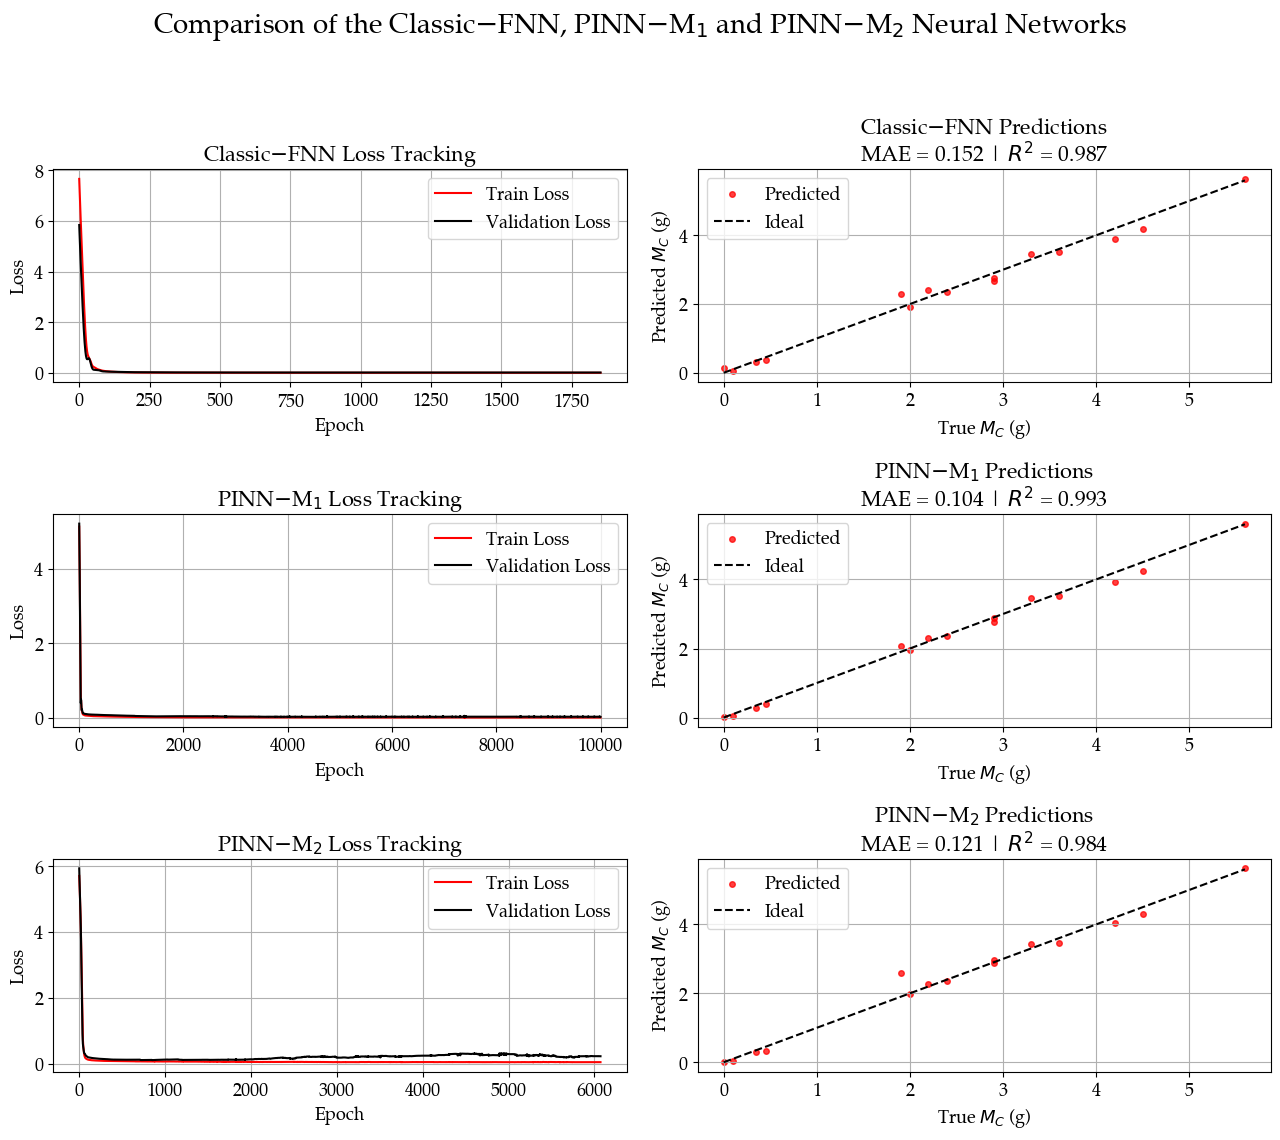

In [14]:
### GRAPHICAL PLOT SET UP###

## Importing necessary libraries ##

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.font_manager as fm

## Optional font (Palatia) ##
font_path = "/content/Palatia.ttf"
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams["font.family"] = prop.get_name()
else:
    print("Palatia.ttf not found; using default matplotlib font.")

plt.rcParams["font.size"] = 13
plt.rcParams["text.usetex"] = False

## Graphical plot function set-up ##
def plot_row(ax_loss, ax_pred, train_loss, val_loss, y_true, y_pred, model_name):
    ## Loss Curve Set up ##
    ax_loss.plot(train_loss, label="Train Loss", color="red")
    if val_loss is not None:
        ax_loss.plot(val_loss, label="Validation Loss", color="black")
    ax_loss.set_title(f"{model_name} Loss Tracking")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss")
    ax_loss.grid(True)
    ax_loss.legend()

    ## Predicted versus the True value of the mass of carbon deposited ##
    ax_pred.scatter(y_true, y_pred, s=16, alpha=0.75, color="red", label="Predicted")
    lo, hi = float(np.min(y_true)), float(np.max(y_true))
    ax_pred.plot([lo, hi], [lo, hi], linestyle="--", color="black", label="Ideal")

    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    ax_pred.set_title(f"{model_name} Predictions\nMAE = {mae:.3f} | $R^2$ = {r2:.3f}")
    ax_pred.set_xlabel("True $M_C$ (g)")
    ax_pred.set_ylabel("Predicted $M_C$ (g)")
    ax_pred.grid(True)
    ax_pred.legend()


fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(13, 12))
plt.subplots_adjust(hspace=0.5, wspace=0.35)
fig.suptitle("Comparison of the Classic$-$FNN, PINN$-$M$_1$ and PINN$-$M$_2$ Neural Networks", fontsize=20)


(ax1, ax2), (ax3, ax4), (ax5, ax6) = axes

### Classic-FNN ###
plot_row(
    ax1, ax2,
    fnn_hist["train_loss"], fnn_hist["val_loss"],
    fnn_hist["y_true"], fnn_hist["y_pred"],
    "Classic$-$FNN"
)

### PINN_M1 ###
plot_row(
    ax3, ax4,
    pinn1_hist["train_loss"], pinn1_hist["val_loss"],
    pinn1_hist["y_true"], pinn1_hist["y_pred"],
    "PINN$-$M$_1$"
)

### PINN_M2 ###
plot_row(
    ax5, ax6,
    pinn2_hist["train_loss"], pinn2_hist["val_loss"],
    pinn2_hist["y_true"], pinn2_hist["y_pred"],
    "PINN$-$M$_2$"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("All_Models_Comparison_Plots.png", dpi=600)
plt.show()